In [ ]:
import seaborn as sns
import pandas as pd
import ast
import matplotlib.pyplot as plt

### ANALYSIS OF GENRE DISTRIBUTION AND GROWTH

In this phase, the goal is to explore the thematic composition of the dataset. In the genres column, the data were imported as object type (strings), containing textual representations of lists. To proceed with a granular analysis, a process of Data Cleaning and Normalization is necessary.

We use the ast module to convert strings into Python list objects. This step is fundamental to make the data "understandable" to the analysis algorithms.

**Normalization**: Since a single anime can belong to multiple categories (e.g., "Action, Adventure"), we "exploded" the lists into single entities. This operation avoids the bias of considering genre combinations as unique labels, allowing for an accurate count of every single occurrence.

**Global Analysis**: A first bar chart will illustrate the complete distribution of all genres to identify the pillars of the market.

**Evolutionary Focus**: We will analyze the temporal trend of the Top 5 genres by production volumes. To maximize readability, we will use five-year intervals (every 5 years), highlighting the historical growth trends from 1960 to 2023.

In [12]:
details_df = pd.read_parquet("../data/details_clean.parquet")
details_df.head(10)

,mal_id,title,type,status,score,scored_by,start_date,end_date,synopsis,rank,...,themes,demographics,source,rating,episodes,year,producers,explicit_genres,licensors,streaming
0,59356,-Socket-,Movie,Finished Airing,NaN,NaN,2010-01-01 00:00:00+00:00,NaT,A girl with a cord growing out of her back wan...,17086.0,...,[],[],Original,G - All Ages,1.0,2010,[Nagoya Zokei University],[],[],[]
1,56036,......,Music,Finished Airing,6.53,503.0,2023-06-11 00:00:00+00:00,NaT,Music video directed by obmolot for the song ....,NaN,...,[Music],[],Original,PG-13 - Teens 13 or older,1.0,2023,[],[],[],[]
2,2928,.hack//G.U. Returner,OVA,Finished Airing,6.65,9745.0,2007-01-18 00:00:00+00:00,NaT,The characters from previous .hack//G.U. Games...,6366.0,...,[Video Game],[],Game,PG-13 - Teens 13 or older,1.0,2007,"[Bandai Visual, CyberConnect2]",[],[],[]
3,3269,.hack//G.U. Trilogy,Movie,Finished Airing,7.06,15373.0,2007-12-22 00:00:00+00:00,NaT,"Based on the CyberConnect2 HIT GAME, now will ...",4194.0,...,[Video Game],[],Game,PG-13 - Teens 13 or older,1.0,2007,[Bandai Visual],[],"[Funimation, Bandai Entertainment]",[]
4,4469,.hack//G.U. Trilogy: Parody Mode,Special,Finished Airing,6.35,4317.0,2008-03-25 00:00:00+00:00,NaT,A special bonus Parody Mode added to the extra...,8182.0,...,"[Parody, Video Game]",[],Game,PG-13 - Teens 13 or older,1.0,2008,[Bandai Visual],[],[],[]
5,454,.hack//Gift,OVA,Finished Airing,6.09,10021.0,2003-11-16 00:00:00+00:00,NaT,As an expression of gratitude for the heroes o...,9692.0,...,[Video Game],[],Original,R+ - Mild Nudity,1.0,2003,[CyberConnect2],[],[Bandai Entertainment],[]
6,1143,.hack//Intermezzo,Special,Finished Airing,6.51,11616.0,2003-03-28 00:00:00+00:00,NaT,A virtual multiplayer online role-playing game...,7195.0,...,[Video Game],[],Original,PG-13 - Teens 13 or older,1.0,2003,[],[],[Bandai Entertainment],['Crunchyroll']
7,299,.hack//Liminality,OVA,Finished Airing,6.58,17130.0,2002-06-20 00:00:00+00:00,2003-04-10 00:00:00+00:00,"While playing the newly released MMORPG ""The W...",6740.0,...,[Video Game],[],Original,PG-13 - Teens 13 or older,4.0,2002,"[Bandai Visual, Bandai, CyberConnect2]",[],[Bandai Entertainment],[]
8,9332,.hack//Quantum,OVA,Finished Airing,7.11,20412.0,2011-01-28 00:00:00+00:00,2011-04-07 00:00:00+00:00,"Tobias, Mary, and Sakuya challenge the impregn...",3960.0,...,[Video Game],[],Original,PG-13 - Teens 13 or older,3.0,2011,"[Bandai Visual, flying DOG, Showgate, BIGLOBE,...",[],[Funimation],['Crunchyroll']
9,10390,.hack//Quantum: Sore ike! Bokura no Chimuchimu...,Special,Finished Airing,6.29,2810.0,2011-01-28 00:00:00+00:00,2011-04-07 00:00:00+00:00,DVD specials for .hack//Quantum. Main girls ar...,8559.0,...,[Video Game],[],Original,PG-13 - Teens 13 or older,3.0,2011,[Bandai Visual],[],[],[]


In [ ]:
# Comprensione il formato
print("\nFormato colonna genres:")
details_df['genres'].head()


Formato colonna genres:


0                       [Comedy]
1         [Horror, Supernatural]
2    [Adventure, Drama, Fantasy]
3              [Action, Fantasy]
4      [Comedy, Fantasy, Sci-Fi]
Name: genres, dtype: object

This is genre countsSeries([], Name: count, dtype: int64)

Generi più frequenti:
Series([], Name: count, dtype: int64)


IndexError: index 0 is out of bounds for axis 0 with size 0

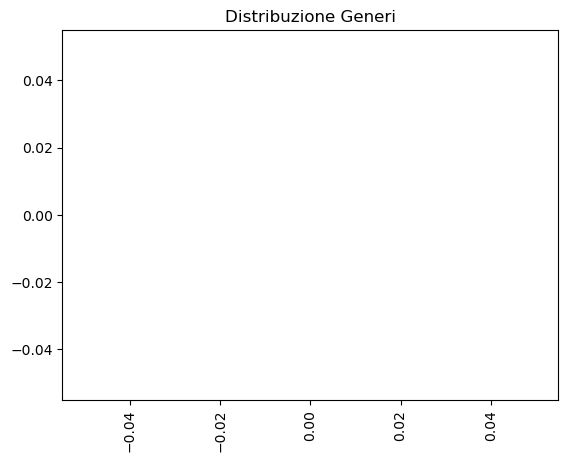

In [ ]:
# Conversione da stringa a lista
genres_cleaned_series = details_df['genres'].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) and x.startswith('[') else x if isinstance(x, list) else [] )

genres_series = genres_cleaned_series.explode()
genre_counts = genres_series.value_counts()

print("\nGeneri più frequenti:")
print(genre_counts)

# Visualizzazione
genre_counts.plot(kind='bar', title='Distribuzione Generi')
plt.ylabel('Numero di Anime')
plt.show()

genre_counts.head(5).plot(kind='bar', title='Distribuzione Top 5 Generi')
plt.ylabel('Numero di Anime')
plt.show()


### Analysis of Historical Genre Growth (1960 - 2023)
In this section, the goal is to analyze how the production of the 5 most popular genres has evolved over time. To ensure an accurate and professional analysis, we adopted a Data Transformation strategy that preserves the integrity of the original dataset.

**Temporary Preprocessing**: We converted the start_date column into datetime objects within local variables. The use of the .dt accessor for year extraction occurred without permanently modifying the original DataFrame, avoiding memory redundancies.

**Data Modularity**: A dedicated support DataFrame was created exclusively for this visualization. This allowed for isolating the genre explosion logic (necessary as the column is of object type) from the main data structure.

**Narrative Visualization**: The time axis division was set with 5-year intervals. This choice allows for highlighting growth cycles in a clear and scanned manner, making the chart an immediate "headline" for the reader.

**Statistical Accuracy**: The analysis covers the period from 1960 to 2023. We excluded data from 2024 onwards because, being an incomplete year, it would have shown a fictitious production drop not representative of real market trends.

/tmp/ipykernel_519051/3494684754.py:31: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='Genere', bbox_to_anchor=(1, 1), loc='upper left')


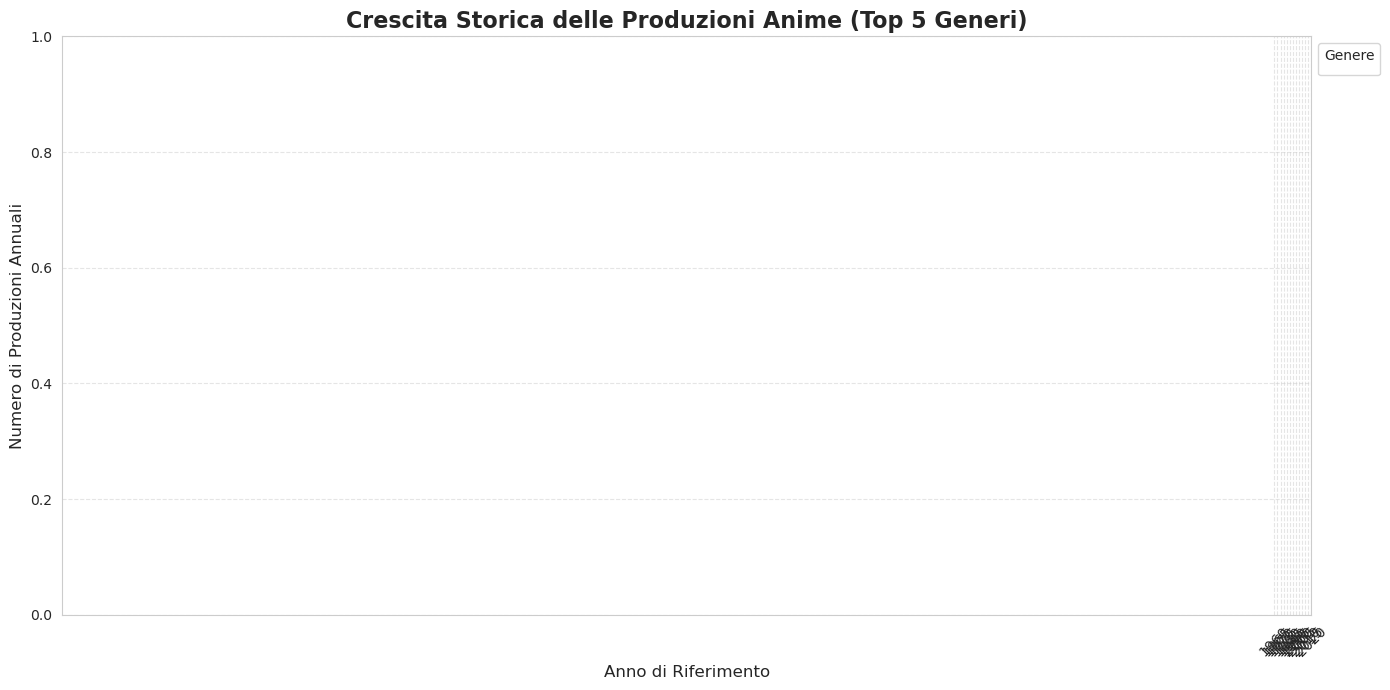

In [ ]:
temp_genres = details_df['genres'].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) 
                                         and x.startswith('[') else x if isinstance(x, list) else [])

temp_datetime = pd.to_datetime(details_df['start_date'], errors='coerce') 
temp_years = temp_datetime.dt.year
# Creazione DataFrame di analisi 
df_growth = pd.DataFrame({'year': temp_years,'genre': temp_genres}).explode('genre')

top_5_labels = df_growth['genre'].value_counts().head(5).index.tolist()
df_top_5 = df_growth[df_growth['genre'].isin(top_5_labels)]

# Raggruppamento annuale 
growth_data = df_top_5[(df_top_5['year'] >= 1960) & (df_top_5['year'] <= 2023)]
growth_pivot = growth_data.groupby(['year', 'genre']).size().unstack(fill_value=0)

plt.figure(figsize=(14, 7))
sns.set_style("whitegrid")


sns.lineplot(data=growth_pivot, linewidth=2.5, alpha=0.9, dashes=False)

plt.title('Crescita Storica delle Produzioni Anime (Top 5 Generi)', fontsize=16, fontweight='bold')
plt.xlabel('Anno di Riferimento', fontsize=12)
plt.ylabel('Numero di Produzioni Annuali', fontsize=12)

years_range = range(1960, 2025, 5)
plt.xticks(ticks=years_range, rotation=45)

# Griglia e Legenda
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Genere', bbox_to_anchor=(1, 1), loc='upper left')

plt.tight_layout()
plt.show()

### SCORE DISTRIBUTION
Distribution based on the score of the various anime

In [ ]:
# Statistiche generali sui voti
print("Distribuzione dello Score:")
display(details_df['score'].describe()) 
# Controlliamo se ci sono voti anomali 
outliers_score = details_df.query('score > 10 or score <= 0')
print(f"Numero di outlier rilevati nello score: {len(outliers_score)}")

if len(outliers_score) > 0:
    display(outliers_score)